In [1]:
library(tidyverse)
library(lubridate)
library(quantmod)

getSymbols("AAPL",
    src = "yahoo", 
    from = as.Date("2025-01-01")
)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: xts

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric



######################### Warning from 'xts' package ##########################
#                                                                             #
# The dplyr lag() function breaks how base R's lag() function is supposed to  #
# work, which breaks lag(my_xts). Calls to lag(my_xts) that

[1] "AAPL"

In [2]:
AAPL

           AAPL.Open AAPL.High AAPL.Low AAPL.Close AAPL.Volume AAPL.Adjusted
2025-01-02    248.93    249.10   241.82     243.85    55740700      242.3019
2025-01-03    243.36    244.18   241.89     243.36    40244100      241.8150
2025-01-06    244.31    247.33   243.20     245.00    45045600      243.4446
2025-01-07    242.98    245.55   241.35     242.21    40856000      240.6723
2025-01-08    241.92    243.71   240.05     242.70    37628900      241.1592
2025-01-10    240.01    240.16   233.00     236.85    61710900      235.3464
2025-01-13    233.53    234.67   229.72     234.40    49630700      232.9119
2025-01-14    234.75    236.12   232.47     233.28    39435300      231.7990
2025-01-15    234.64    238.96   234.43     237.87    39832000      236.3599
2025-01-16    237.35    238.01   228.03     228.26    71759100      226.8109
       ...                                                                  
2026-06-05    312.86    315.17   307.15     307.34    65310500      307.3400

In [3]:
class(AAPL)

[1] "xts" "zoo"

In [4]:
aapl_tbl <- as_tibble(AAPL, rownames = "date") |>
  rename_with(~ sub("AAPL\\.", "", .x)) |>
  mutate(date = as.Date(date))

aapl_tbl

date,Open,High,Low,Close,Volume,Adjusted
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2025-01-02,248.93,249.10,241.82,243.85,55740700,242.3019
2025-01-03,243.36,244.18,241.89,243.36,40244100,241.8150
2025-01-06,244.31,247.33,243.20,245.00,45045600,243.4446
2025-01-07,242.98,245.55,241.35,242.21,40856000,240.6723
2025-01-08,241.92,243.71,240.05,242.70,37628900,241.1592
2025-01-10,240.01,240.16,233.00,236.85,61710900,235.3464
2025-01-13,233.53,234.67,229.72,234.40,49630700,232.9119
2025-01-14,234.75,236.12,232.47,233.28,39435300,231.7990
2025-01-15,234.64,238.96,234.43,237.87,39832000,236.3599


In [7]:
aapl_tbl |> write_csv("AAPL.csv")

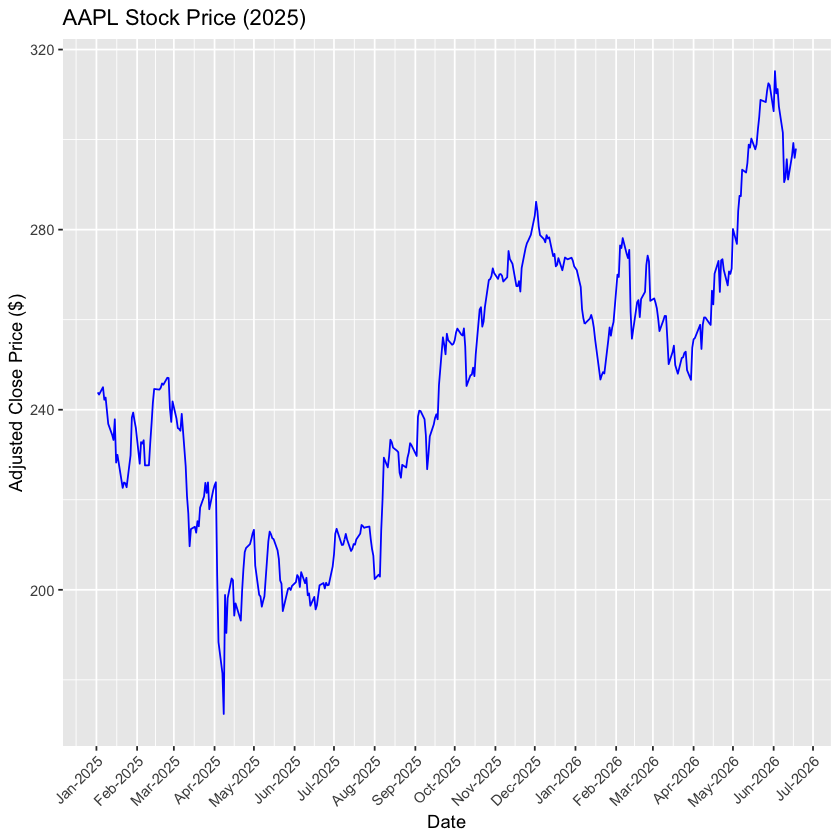

In [5]:
line_plot <- ggplot(aapl_tbl, aes(x = date, y = Close)) +
  geom_line(color = "blue") +
  scale_x_date(date_breaks = "1 months", date_labels = "%b-%Y") +
  labs(
    title = "AAPL Stock Price (2025)",
    x = "Date", 
    y = "Adjusted Close Price ($)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

line_plot

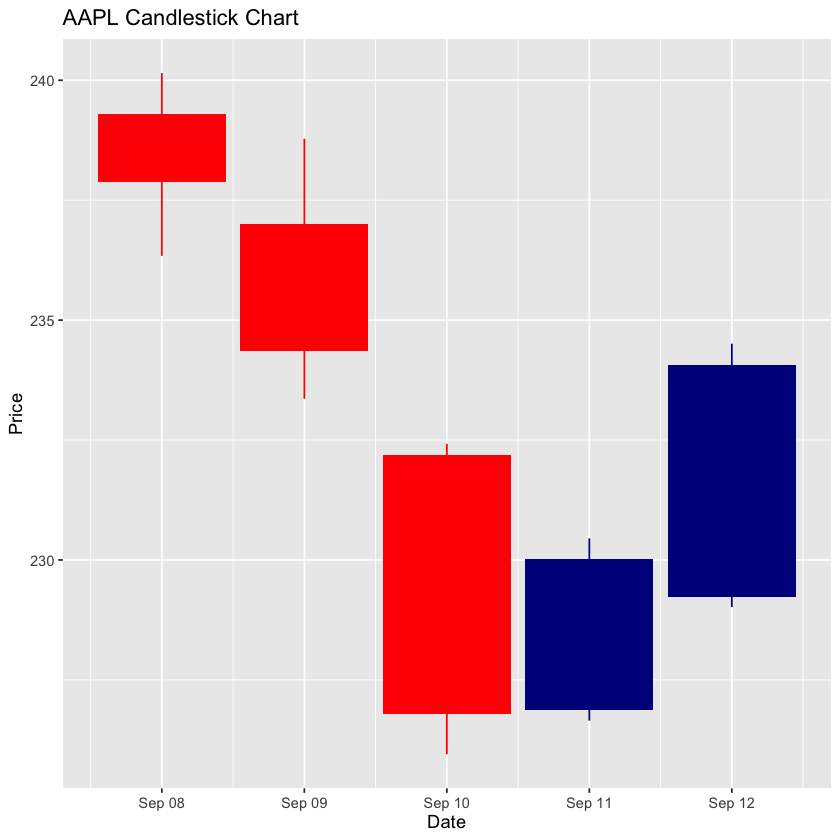

In [6]:
aapl_tbl_sub <- aapl_tbl |>
  filter(date>=as.Date("2025-09-08") & date<=as.Date("2025-09-12"))

candle_sticks <- ggplot(aapl_tbl_sub, aes(x = date, open = Open, high = High, low = Low, close = Close)) +
  tidyquant::geom_candlestick() +
  labs(
    title = "AAPL Candlestick Chart",
    y = "Price", 
    x = "Date"
  )

candle_sticks